# Metrik ranking dan jebakan evaluasi

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab06_evaluasi/01_metrik_ranking_dan_jebakan_evaluasi.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 6 · Kode 6.x (metrik prediksi dan ketepatan daftar)

**Tujuan belajar**

- Menghitung MAE/RMSE, Hit Rate, Precision, Recall, F1, MRR, MAP, dan nDCG, dan memeriksanya pada contoh yang bisa dihitung tangan.
- Melihat bagaimana K dan jenis metrik dapat mengubah urutan model.
- Memahami mengapa evaluasi dengan negatif tersampel dapat menyesatkan.

> **Catatan jujur.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

## 1. Kode dari buku

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def mae_rmse(r, r_hat):
    e = np.asarray(r, float) - np.asarray(r_hat, float)
    return np.abs(e).mean(), np.sqrt((e ** 2).mean())


def _hits(ranked, rel, K):
    return np.array([1.0 if i in rel else 0.0 for i in ranked[:K]])


def hit_rate(ranked, rel, K):
    return float(_hits(ranked, rel, K).sum() > 0)


def precision(ranked, rel, K):
    return _hits(ranked, rel, K).sum() / K


def recall(ranked, rel, K):
    return _hits(ranked, rel, K).sum() / max(len(rel), 1)


def f1(ranked, rel, K):
    p, r = precision(ranked, rel, K), recall(ranked, rel, K)
    return 0.0 if p + r == 0 else 2 * p * r / (p + r)


def reciprocal_rank(ranked, rel, K):
    h = _hits(ranked, rel, K)
    return 0.0 if h.sum() == 0 else 1.0 / (np.argmax(h) + 1)


def average_precision(ranked, rel, K):
    h = _hits(ranked, rel, K)
    prec_at_k = np.cumsum(h) / np.arange(1, len(h) + 1)
    return (h * prec_at_k).sum() / max(min(len(rel), K), 1)


def ndcg(ranked, rel, K):
    """rel: {item: tingkat relevansi}. Perolehan 2^g - 1 (biner: g = 1)."""
    disc = 1.0 / np.log2(np.arange(2, K + 2))
    gains = np.array([2.0 ** rel.get(i, 0) - 1 if i in rel else 0.0 for i in ranked[:K]])
    ideal = np.sort([2.0 ** g - 1 for g in rel.values()])[::-1][:K]
    idcg = (ideal * disc[:len(ideal)]).sum()
    return 0.0 if idcg == 0 else (gains * disc[:len(gains)]).sum() / idcg

## 2. Contoh yang dapat dihitung tangan

Daftar rekomendasi `[a, b, c, d, e]`. Item relevan: `{b, e, z}` (satu relevan, `z`, tidak muncul sama sekali). Pada K = 5:

- Precision = 2/5 = 0,4; Recall = 2/3; MRR = 1/2 (relevan pertama di posisi 2).
- AP = (1/min(3,5)) · (1/2 + 2/5) = 0,3.
- nDCG (biner) = (1/log₂3 + 1/log₂6) / (1 + 1/log₂3 + 1/log₂4).

In [2]:
ranked = ["a", "b", "c", "d", "e"]
rel = {"b", "e", "z"}
print("P@5", precision(ranked, rel, 5), "| R@5", recall(ranked, rel, 5), "| MRR", reciprocal_rank(ranked, rel, 5))
print("AP@5", average_precision(ranked, rel, 5), "| HR@5", hit_rate(ranked, rel, 5))
rel_g = {"b": 1, "e": 1, "z": 1}
manual = (1/np.log2(3) + 1/np.log2(6)) / (1 + 1/np.log2(3) + 1/np.log2(4))
print("nDCG@5", ndcg(ranked, rel_g, 5), "| manual", manual)

assert abs(precision(ranked, rel, 5) - 0.4) < 1e-12
assert abs(recall(ranked, rel, 5) - 2/3) < 1e-12
assert abs(reciprocal_rank(ranked, rel, 5) - 0.5) < 1e-12
assert abs(average_precision(ranked, rel, 5) - 0.3) < 1e-12
assert abs(ndcg(ranked, rel_g, 5) - manual) < 1e-12

P@5 0.4 | R@5 0.6666666666666666 | MRR 0.5
AP@5 0.3 | HR@5 1.0
nDCG@5 0.4776237035032179 | manual 0.4776237035032179


## 3. Simulasi: tiga model, banyak metrik

Dunia: 500 item dengan popularitas Zipf, 300 pengguna dengan selera laten. Item relevan bagi pengguna = 5 item uji yang disampel dari selera pengguna dengan peluang naik terhadap popularitas. Tiga model:

- **Populer**: peringkat berdasarkan popularitas global.
- **Personal-berderau**: skor selera sebenarnya + derau besar.
- **Personal-jernih**: skor selera sebenarnya + derau kecil.

(Model "personal" di sini bukan algoritma nyata; mereka hanya pembuat skor dengan kualitas berbeda yang dikendalikan, supaya perilaku *metrik* terlihat.)

In [3]:
rng = np.random.default_rng(0)
N_I, N_U, N_REL = 500, 300, 5
pop = 1.0 / np.arange(1, N_I + 1) ** 0.8
pop = rng.permutation(pop / pop.sum())                       # popularitas global per item
taste = rng.normal(0, 1, (N_U, N_I))                        # selera laten pengguna
logit_rel = 1.2 * taste + 1.0 * np.log(pop / pop.mean())     # peluang relevan: selera + popularitas
relevan = []
for u in range(N_U):
    p = np.exp(logit_rel[u] - logit_rel[u].max()); p /= p.sum()
    relevan.append(set(rng.choice(N_I, N_REL, replace=False, p=p)))

def peringkat(skor_fn):
    return [list(np.argsort(-skor_fn(u))) for u in range(N_U)]

model = {
    "Populer":          peringkat(lambda u: pop),
    "Personal-berderau": peringkat(lambda u: taste[u] + rng.normal(0, 2.5, N_I)),
    "Personal-jernih":  peringkat(lambda u: logit_rel[u] + rng.normal(0, 0.5, N_I)),
}

def tabel_metrik(model, K):
    rows = {}
    for nm, R in model.items():
        rows[nm] = {m.__name__: np.mean([m(R[u], relevan[u], K) for u in range(N_U)])
                    for m in (hit_rate, precision, recall, reciprocal_rank, average_precision)}
        rows[nm]["ndcg"] = np.mean([ndcg(R[u], {i: 1 for i in relevan[u]}, K) for u in range(N_U)])
    return pd.DataFrame(rows).T

for K in (5, 20, 100):
    print(f"\n=== K = {K} ==="); print(tabel_metrik(model, K).round(3).to_string())


=== K = 5 ===
                   hit_rate  precision  recall  reciprocal_rank  average_precision   ndcg
Populer               0.613      0.157   0.157            0.385              0.099  0.178
Personal-berderau     0.130      0.029   0.029            0.062              0.015  0.029
Personal-jernih       0.743      0.235   0.235            0.536              0.168  0.272

=== K = 20 ===
                   hit_rate  precision  recall  reciprocal_rank  average_precision   ndcg
Populer               0.857      0.080   0.319            0.412              0.128  0.255
Personal-berderau     0.363      0.022   0.087            0.084              0.021  0.057
Personal-jernih       0.930      0.106   0.424            0.557              0.211  0.363

=== K = 100 ===
                   hit_rate  precision  recall  reciprocal_rank  average_precision   ndcg
Populer               0.987      0.029   0.584            0.415              0.145  0.337
Personal-berderau     0.863      0.017   0.333      

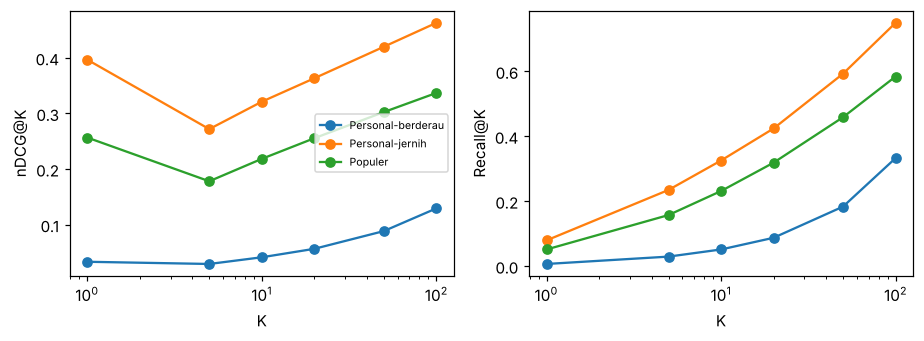

In [4]:
rows = []
for K in (1, 5, 10, 20, 50, 100):
    t = tabel_metrik(model, K)
    for nm in model:
        rows.append({"K": K, "model": nm, "ndcg": t.loc[nm, "ndcg"], "recall": t.loc[nm, "recall"]})
res = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.2))
for nm, g in res.groupby("model"):
    ax[0].plot(g.K, g.ndcg, marker="o", label=nm); ax[1].plot(g.K, g.recall, marker="o", label=nm)
ax[0].set(xlabel="K", ylabel="nDCG@K", xscale="log"); ax[1].set(xlabel="K", ylabel="Recall@K", xscale="log")
ax[0].legend(fontsize=7); fig.tight_layout()

t10 = tabel_metrik(model, 10)
assert t10.loc["Personal-jernih", "ndcg"] > t10.loc["Populer", "ndcg"]
assert t10.loc["Personal-jernih", "ndcg"] > t10.loc["Personal-berderau", "ndcg"]

**Interpretasi.** Model jernih unggul di semua K, dan model berderau paling buruk. Hit Rate menjenuh: pada K = 100 ia sudah 0,99 (Populer) dan 1,00 (jernih), sehingga hampir tidak membedakan keduanya, padahal recall@100 (0,58 vs 0,75) dan nDCG masih membedakan jelas. Jadi metrik yang menjenuh pada K besar kehilangan daya pembeda; pilih K dan metrik yang sesuai skenario tampilan. Perhatikan juga bahwa model Populer *tidak sebodoh itu* di sini karena relevansi dalam simulasi memang dipengaruhi popularitas (parameter `1.0 * log(pop)`); pada dataset nyata, seberapa kuat bias popularitas pada data uji adalah hal yang harus diukur, bukan diasumsikan.

## 4. Jebakan: evaluasi dengan negatif tersampel

Praktik umum: untuk tiap item uji, ambil 99 item negatif acak lalu peringkatkan 100 kandidat itu. Ini murah, tetapi apakah urutan model sama dengan evaluasi peringkat penuh (seluruh katalog)? Bandingkan Hit Rate@10 pada kedua protokol.

In [5]:
def hr_penuh(skor_fn, K=10):
    h = []
    for u in range(N_U):
        s = skor_fn(u)
        ranked = np.argsort(-s)[:K]
        h += [i in set(ranked) for i in relevan[u]]
    return float(np.mean(h))

def hr_sampel(skor_fn, K=10, n_neg=99, seed=0):
    r = np.random.default_rng(seed); h = []
    for u in range(N_U):
        s = skor_fn(u)
        non_rel = np.array([i for i in range(N_I) if i not in relevan[u]])
        for i in relevan[u]:
            neg = r.choice(non_rel, n_neg, replace=False)
            rank = (s[neg] > s[i]).sum()          # peringkat item uji di antara 100 kandidat
            h.append(rank < K)
    return float(np.mean(h))

skor = {
    "Populer": lambda u: pop,
    "Personal-berderau": lambda u, _r=np.random.default_rng(5): taste[u] + _r.normal(0, 2.5, N_I),
    "Personal-jernih": lambda u, _r=np.random.default_rng(6): logit_rel[u] + _r.normal(0, 0.5, N_I),
}
cmp_ = pd.DataFrame({nm: {"HR@10 penuh": hr_penuh(f), "HR@10 sampel (99 neg.)": hr_sampel(f)} for nm, f in skor.items()}).T
print(cmp_.round(3))
assert (cmp_["HR@10 sampel (99 neg.)"] > cmp_["HR@10 penuh"]).all()      # sampel selalu menggembungkan angka

                   HR@10 penuh  HR@10 sampel (99 neg.)
Populer                  0.231                   0.467
Personal-berderau        0.049                   0.203
Personal-jernih          0.306                   0.586


**Interpretasi.** Evaluasi tersampel menggembungkan angka mutlak secara besar-besaran: lawan yang dihadapi hanya 99 item, bukan 499. Itu sebabnya angka dari protokol tersampel **tidak boleh dibandingkan** dengan angka dari protokol penuh atau dengan paper lain yang memakai protokol berbeda. Urutan antar model bisa tetap sama pada simulasi ini, tetapi literatur melaporkan kasus yang urutannya berbalik. Prinsip aman: laporkan protokol, gunakan peringkat penuh bila memungkinkan, dan jangan membandingkan angka lintas protokol.

## Pertanyaan refleksi

1. Pada contoh tangan, bagaimana nilai AP@5 berubah bila item `z` dihitung sebagai relevan yang 'tidak muncul' vs. dikeluarkan dari himpunan relevan? Mengapa penyebut `min(|rel|, K)` dipilih?
2. Naikkan `N_REL` dari 5 ke 50. Metrik mana yang paling terpengaruh, dan mengapa?
3. Ganti negatif acak pada evaluasi tersampel dengan negatif yang disampel sesuai popularitas. Bagaimana jarak antar protokol berubah?